### **CPU Quantization & Ablation Analysis**

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import display

if not (Path.cwd() / "src").is_dir() and (Path.cwd().parent / "src").is_dir():
    os.chdir(Path.cwd().parent)

%load_ext autoreload
%autoreload 2

from src.config import QUANTIZATION_DIR
from src.utils.visualization import (
    load_quantization_reports,
    plot_ptq_variant_ablation_dashboard,
    plot_quantization_ablation_dashboard,
    plot_quantization_curves,
)

EVAL_SPLIT = "val"
REPORTS_DIR = QUANTIZATION_DIR / "reports" / EVAL_SPLIT

results_df, metadata = load_quantization_reports(QUANTIZATION_DIR, eval_split=EVAL_SPLIT)

### **Environment, Calibration & Head Protection Provenance**

In [32]:
env = metadata.get("environment", {})
cal = metadata.get("calibration", {})
onnx_cfg = metadata.get("onnx_quantization", {})
excluded_map = onnx_cfg.get("excluded_nodes_by_resolution", {})

provenance_df = pd.DataFrame([
    {"Item": "Weights SHA256", "Value": metadata.get("source_weights_sha256")},
    {"Item": "Eval Split", "Value": metadata.get("eval_split")},
    {"Item": "Train-Only Calibration Images", "Value": f"{cal.get('actual_images')} (max={cal.get('max_images')}, seed={cal.get('seed')})"},
    {"Item": "ONNX PTQ Config", "Value": f"{onnx_cfg.get('format')} {onnx_cfg.get('activation_type')}/{onnx_cfg.get('weight_type')} per_channel={onnx_cfg.get('per_channel')} reduce_range={onnx_cfg.get('reduce_range')} ({onnx_cfg.get('calibrate_method')})"},
    {"Item": "Excluded ONNX Head Nodes", "Value": ", ".join(f"{k}: {len(v)}" for k, v in excluded_map.items())},
    {"Item": "CPU / Platform", "Value": f"{env.get('platform')} | {env.get('machine')} | cores={env.get('cpu_count')}"},
])
display(provenance_df.style.hide(axis="index"))

Item,Value
Weights SHA256,45c4525fcf9a8b18c81e2501a85829d639fd88ea364213988f351f8a37b4f263
Eval Split,val
Train-Only Calibration Images,"500 (max=500, seed=42)"
ONNX PTQ Config,QDQ QUInt8/QInt8 per_channel=True reduce_range=False (MinMax)
Excluded ONNX Head Nodes,"1280: 66, 640: 66"
CPU / Platform,Windows-10-10.0.19045-SP0 | AMD64 | cores=8


### **Stage-by-Stage Size, CPU Speed & Threshold-Free Quality**

In [33]:
main_cols = [
    "imgsz",
    "stage",
    "size_mb",
    "compute_mean_ms",
    "compute_fps",
    "e2e_mean_ms",
    "e2e_p95_ms",
    "e2e_fps",
    "rss_mb",
    "mAP50",
    "mAP50-95",
    "AP50",
    "AP50_small",
    "Recall_small (raw)",
    "Neg FPR @ R>=0.85 (%)",
    "Mean Neg FA Rate (%)",
    "tp_conf_median",
    "tp_recall_ge_0_30",
]
present_main = [col for col in main_cols if col in results_df.columns]
display(
    results_df[present_main]
    .style
    .format(precision=4, na_rep="-")
    .hide(axis="index")
)

imgsz,stage,size_mb,compute_mean_ms,compute_fps,e2e_mean_ms,e2e_p95_ms,e2e_fps,rss_mb,mAP50,mAP50-95,AP50,AP50_small,Recall_small (raw),Neg FPR @ R>=0.85 (%),Mean Neg FA Rate (%),tp_conf_median,tp_recall_ge_0_30
1280,pytorch_fp32,5.2475,288.7651,3.4630,276.7233,299.9891,3.6137,2536.1836,-,-,-,-,-,-,-,-,-
1280,onnx_fp32,9.8318,163.5219,6.1154,227.8002,304.0732,4.3898,3278.6445,0.9590,0.8200,0.9508,0.9132,0.9623,4.0541,22.8638,0.9757,0.9399
1280,onnx_int8,3.4752,227.6651,4.3924,279.1114,295.4035,3.5828,2713.2695,0.9168,0.7394,0.8978,0.8774,0.9623,13.5135,7.5894,0.8252,0.8054
1280,openvino_fp32,9.8131,176.1301,5.6776,105.5452,122.1032,9.4746,3417.5273,0.9600,0.8176,0.9523,0.9175,0.9623,5.4054,22.9730,0.9751,0.9399
1280,openvino_int8,3.4752,166.6679,6.0000,425.3181,580.4333,2.3512,3492.3438,0.9545,0.7967,0.9499,0.9244,0.9623,9.4595,19.9700,0.9731,0.9381
640,pytorch_fp32,5.2475,106.7932,9.3639,111.7618,120.5726,8.9476,1862.2461,-,-,-,-,-,-,-,-,-
640,onnx_fp32,9.3508,54.2748,18.4247,82.8102,85.1903,12.0758,2064.3555,0.7821,0.6280,0.7578,0.2564,0.2642,-,1.2558,0.9515,0.6893
640,onnx_int8,2.9942,42.3429,23.6167,70.1107,74.7308,14.2632,1983.1992,0.7273,0.5544,0.6931,0.2060,0.2075,-,0.8190,0.5000,0.4792
640,openvino_fp32,9.5243,43.8127,22.8244,36.8574,40.9029,27.1316,2191.2500,0.7824,0.6274,0.7571,0.2591,0.2642,-,1.2558,0.9517,0.6887
640,openvino_int8,3.1865,19.0331,52.5400,68.3680,103.2923,14.6267,2033.7305,0.8020,0.6253,0.7779,0.4626,0.4906,-,1.0647,0.9521,0.7018


### **Quantization Deltas (FP32 -> INT8 Within Resolution) & Speedups**

In [34]:
delta_cols = [
    "imgsz",
    "stage",
    "size_ratio_vs_pt",
    "size_reduction_pct_vs_fp32",
    "speedup_compute_vs_fp32",
    "speedup_e2e_vs_pt",
    "ap50_delta_vs_fp32",
    "ap50_small_delta_vs_fp32",
    "map50_delta_vs_fp32",
    "map50_95_delta_vs_fp32",
    "neg_fpr_at_r85_delta_vs_fp32",
]
present_deltas = [col for col in delta_cols if col in results_df.columns]
display(
    results_df[present_deltas]
    .style
    .format(precision=4, na_rep="-")
    .hide(axis="index")
)

imgsz,stage,size_ratio_vs_pt,size_reduction_pct_vs_fp32,speedup_compute_vs_fp32,speedup_e2e_vs_pt,ap50_delta_vs_fp32,ap50_small_delta_vs_fp32,map50_delta_vs_fp32,map50_95_delta_vs_fp32,neg_fpr_at_r85_delta_vs_fp32
1280,pytorch_fp32,1.0000,-,-,1.0000,-,-,-,-,-
1280,onnx_fp32,1.8736,-,-,1.2148,-,-,-,-,-
1280,onnx_int8,0.6623,64.6532,0.7183,0.9914,-0.0530,-0.0358,-0.0422,-0.0805,9.4595
1280,openvino_fp32,1.8700,-,-,2.6218,-,-,-,-,-
1280,openvino_int8,0.6623,64.5856,1.0568,0.6506,-0.0025,0.0069,-0.0055,-0.0209,4.0541
640,pytorch_fp32,1.0000,-,-,1.0000,-,-,-,-,-
640,onnx_fp32,1.7819,-,-,1.3496,-,-,-,-,-
640,onnx_int8,0.5706,67.9788,1.2818,1.5941,-0.0647,-0.0504,-0.0548,-0.0736,-
640,openvino_fp32,1.8150,-,-,3.0323,-,-,-,-,-
640,openvino_int8,0.6072,66.5436,2.3019,1.6347,0.0207,0.2035,0.0196,-0.0021,-


### **Scale-Stratified Breakdown (Small / Medium / Large)**

In [35]:
scale_rows = []
for key, detail in (metadata.get("stage_details") or {}).items():
    stage_name, _, res_str = key.rpartition("_")
    for entry in detail.get("by_scale", []):
        scale_rows.append({"imgsz": int(res_str), "stage": stage_name, **entry})

if scale_rows:
    scale_df = pd.DataFrame(scale_rows).sort_values(["imgsz", "Scale", "stage"], ascending=[False, True, True])
    display(scale_df.style.format(precision=4, na_rep="-").hide(axis="index"))

imgsz,stage,Scale,GT,AP50,Max Recall (raw),Recall @ Max-F1,Recall @ Neg FPR<=5%
1280,onnx_fp32,large,1150,0.9751,0.9783,0.9635,0.8991
1280,onnx_int8,large,1150,0.9250,0.9339,0.9296,0.5496
1280,openvino_fp32,large,1150,0.9756,0.9783,0.9565,0.8887
1280,openvino_int8,large,1150,0.9716,0.9774,0.9565,0.8452
1280,onnx_fp32,medium,477,0.8917,0.9057,0.8679,0.7547
1280,onnx_int8,medium,477,0.8296,0.8512,0.8323,0.3816
1280,openvino_fp32,medium,477,0.8948,0.9099,0.8658,0.7233
1280,openvino_int8,medium,477,0.8995,0.9140,0.8847,0.7358
1280,onnx_fp32,small,53,0.9132,0.9623,0.9623,0.6792
1280,onnx_int8,small,53,0.8774,0.9623,0.9434,0.5660


### **Ablation Dashboard & Threshold-Free Trade-Off Curves**

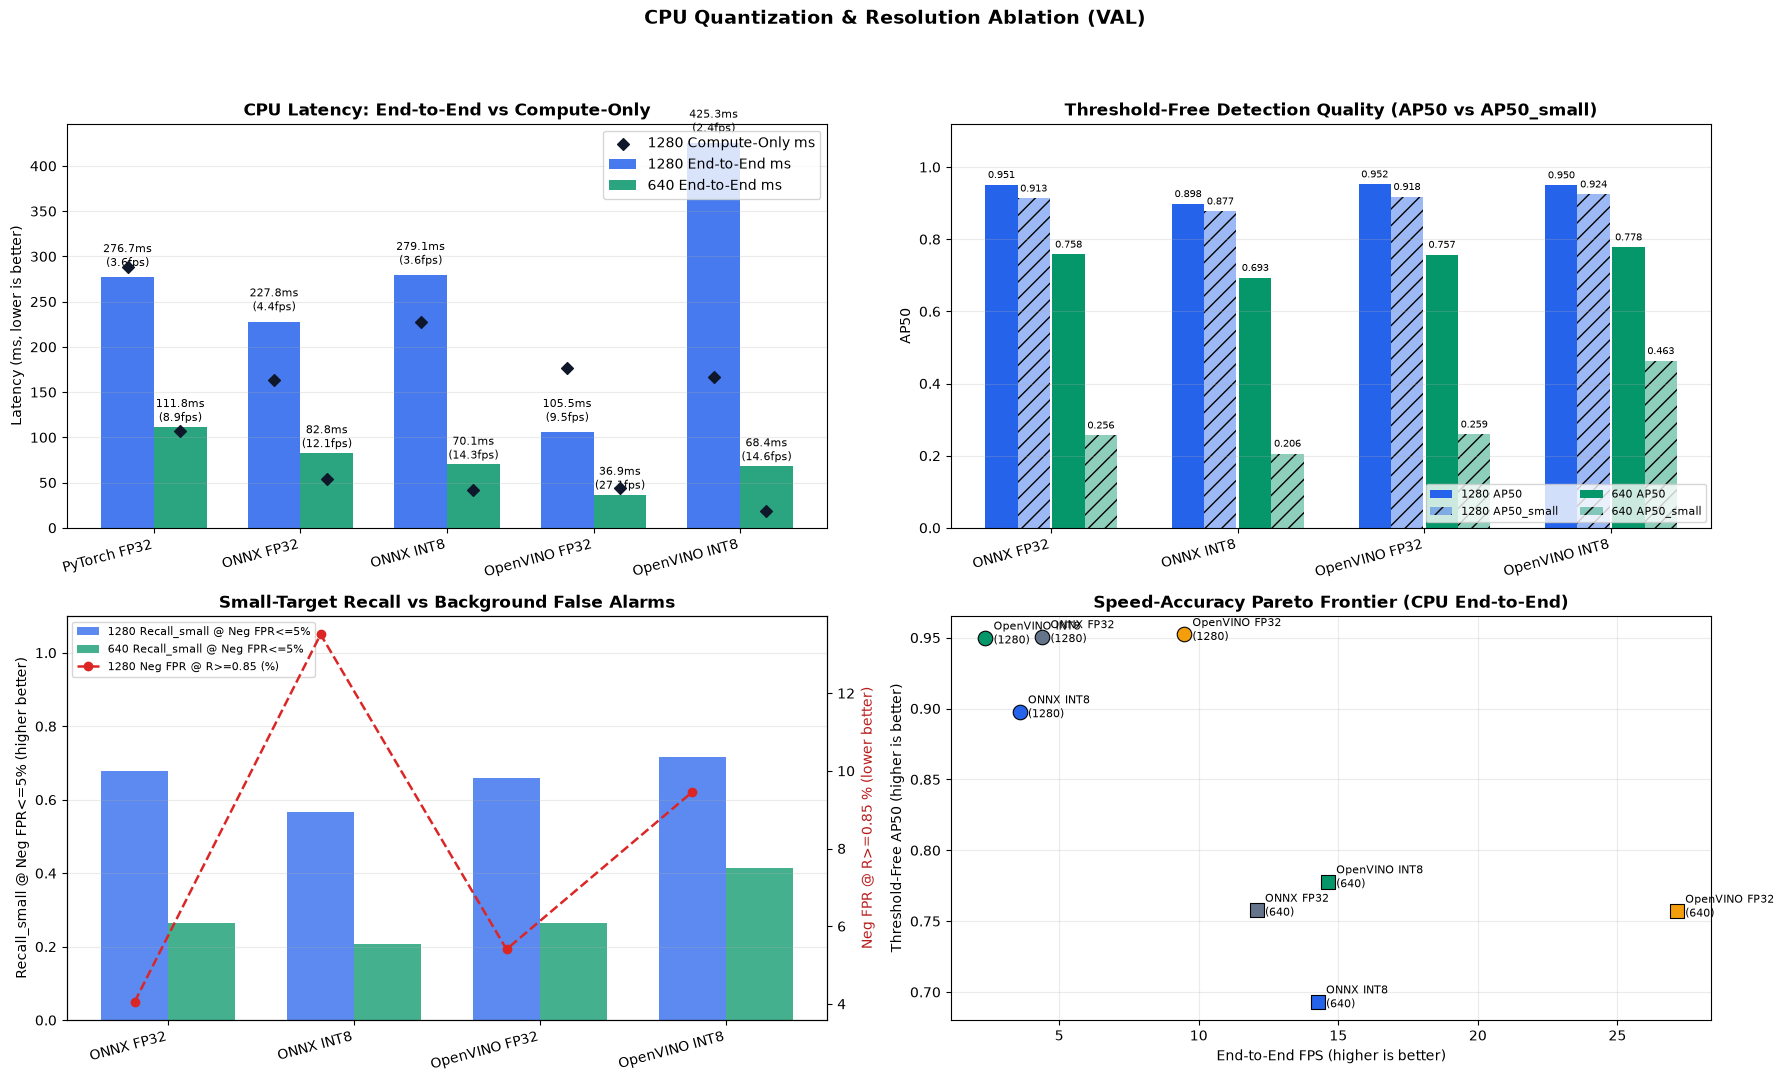

In [36]:
plot_quantization_ablation_dashboard(
    results_df,
    metadata,
    save_path=REPORTS_DIR / "quantization_ablation_dashboard.png",
)

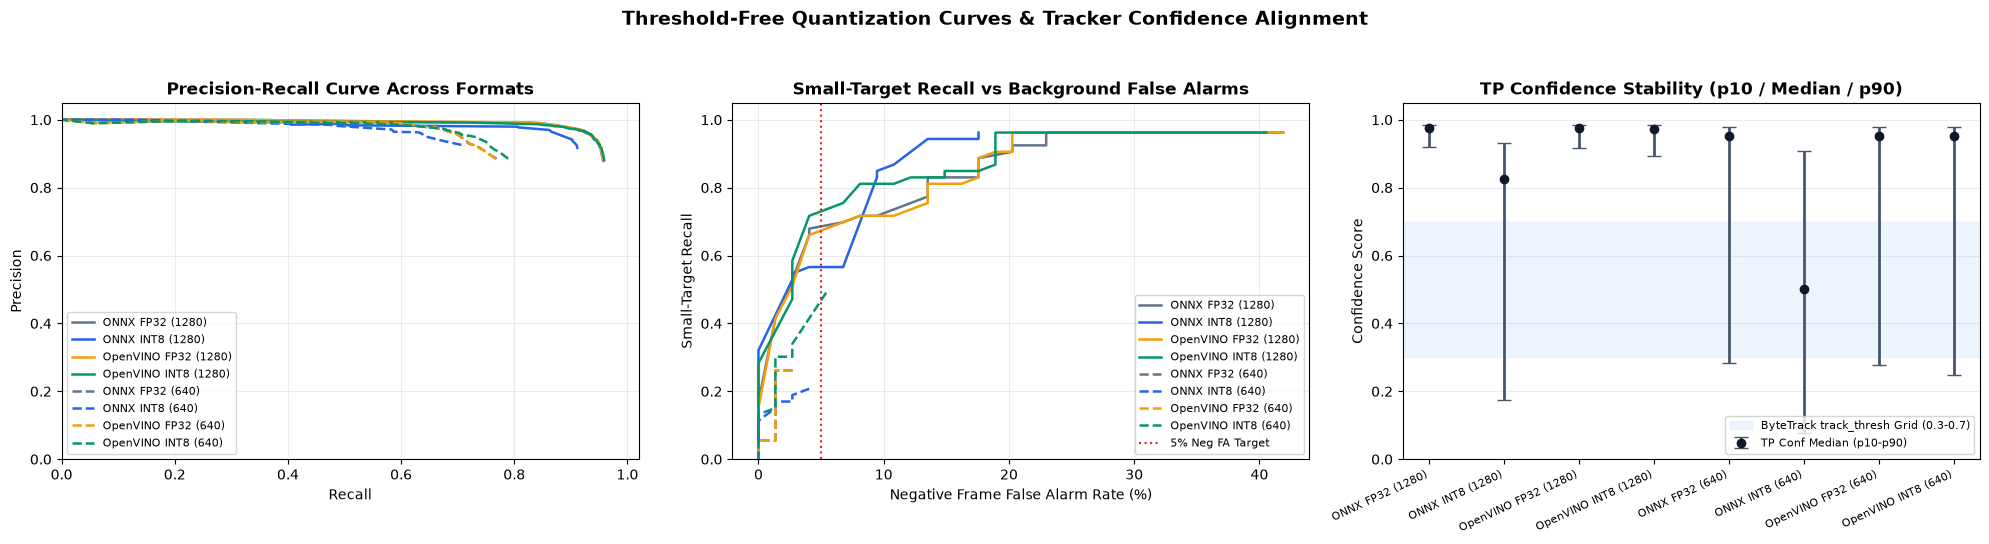

In [37]:
plot_quantization_curves(
    metadata,
    save_path=REPORTS_DIR / "quantization_curves.png",
)

### **PTQ Variant Ablation (Calibration, Head FP32 Protection & NNCF)**

In [38]:
PTQ_SPLIT = "ptq_ablation_val"
PTQ_REPORTS_DIR = QUANTIZATION_DIR / "reports" / PTQ_SPLIT
ptq_df, ptq_meta = load_quantization_reports(QUANTIZATION_DIR, eval_split=PTQ_SPLIT)

ptq_cols = [
    "imgsz", "stage", "status", "size_mb", "compute_mean_ms", "compute_fps",
    "e2e_mean_ms", "e2e_fps", "AP50", "AP50_small", "ap50_delta_vs_fp32",
    "ap50_small_delta_vs_fp32", "Neg FPR @ R>=0.85 (%)", "Recall_small @ Neg FPR<=5%",
    "tp_conf_p10", "tp_conf_median", "tp_conf_p90",
]
ok_ptq_df = ptq_df[ptq_df["status"] == "ok"].copy()
display(
    ok_ptq_df[[c for c in ptq_cols if c in ok_ptq_df.columns]]
    .style.format(precision=4, na_rep="-")
    .hide(axis="index")
)

failed_ptq_df = ptq_df[ptq_df["status"] != "ok"][["imgsz", "stage", "status", "error"]].copy()
if not failed_ptq_df.empty:
    display(failed_ptq_df.style.hide(axis="index"))

imgsz,stage,status,size_mb,compute_mean_ms,compute_fps,e2e_mean_ms,e2e_fps,AP50,AP50_small,ap50_delta_vs_fp32,ap50_small_delta_vs_fp32,Neg FPR @ R>=0.85 (%),Recall_small @ Neg FPR<=5%,tp_conf_p10,tp_conf_median,tp_conf_p90
1280,onnx_fp32,ok,9.8318,163.5219,6.1154,227.8002,4.3898,0.9508,0.9132,-,-,4.0541,0.6792,0.9207,0.9757,0.9849
1280,onnx_int8_minmax_head_int8,ok,3.4752,227.6651,4.3924,279.1114,3.5828,0.8978,0.8774,-0.0530,-0.0358,13.5135,0.5660,0.1748,0.8252,0.9306
1280,onnx_int8_minmax_head_fp32,ok,3.7382,216.6277,4.6162,290.5409,3.4419,0.9299,0.9430,-0.0209,0.0299,5.4054,0.8491,0.8664,0.9759,0.9866
1280,onnx_int8_moving_avg_head_fp32,ok,3.7382,218.3822,4.5791,275.3973,3.6311,0.9358,0.9185,-0.0150,0.0053,9.4595,0.6981,0.8621,0.9698,0.9811
1280,onnx_int8_nncf_head_int8,ok,3.2802,547.2468,1.8273,460.4183,2.1719,0.9489,0.9262,-0.0019,0.0130,8.1081,0.7547,0.9055,0.9752,0.9866
1280,onnx_int8_nncf_head_fp32,ok,3.5696,363.1913,2.7534,430.6103,2.3223,0.9495,0.9267,-0.0014,0.0136,5.4054,0.7170,0.9125,0.9747,0.9841
1280,openvino_fp32,ok,9.8131,176.1301,5.6776,105.5452,9.4746,0.9523,0.9175,-,-,5.4054,0.6604,0.9160,0.9751,0.9844
1280,openvino_int8_ultralytics,ok,3.4752,166.6679,6.0000,425.3181,2.3512,0.9499,0.9244,-0.0025,0.0069,9.4595,0.7170,0.8936,0.9731,0.9844
1280,openvino_int8_nncf_full_bias_head_fp32,ok,3.4753,146.2761,6.8364,400.0401,2.4997,0.9445,0.9254,-0.0079,0.0079,9.4595,0.6604,0.8921,0.9697,0.9829
640,onnx_fp32,ok,9.3508,54.2748,18.4247,82.8102,12.0758,0.7578,0.2564,-,-,-,0.2642,0.2828,0.9515,0.9787


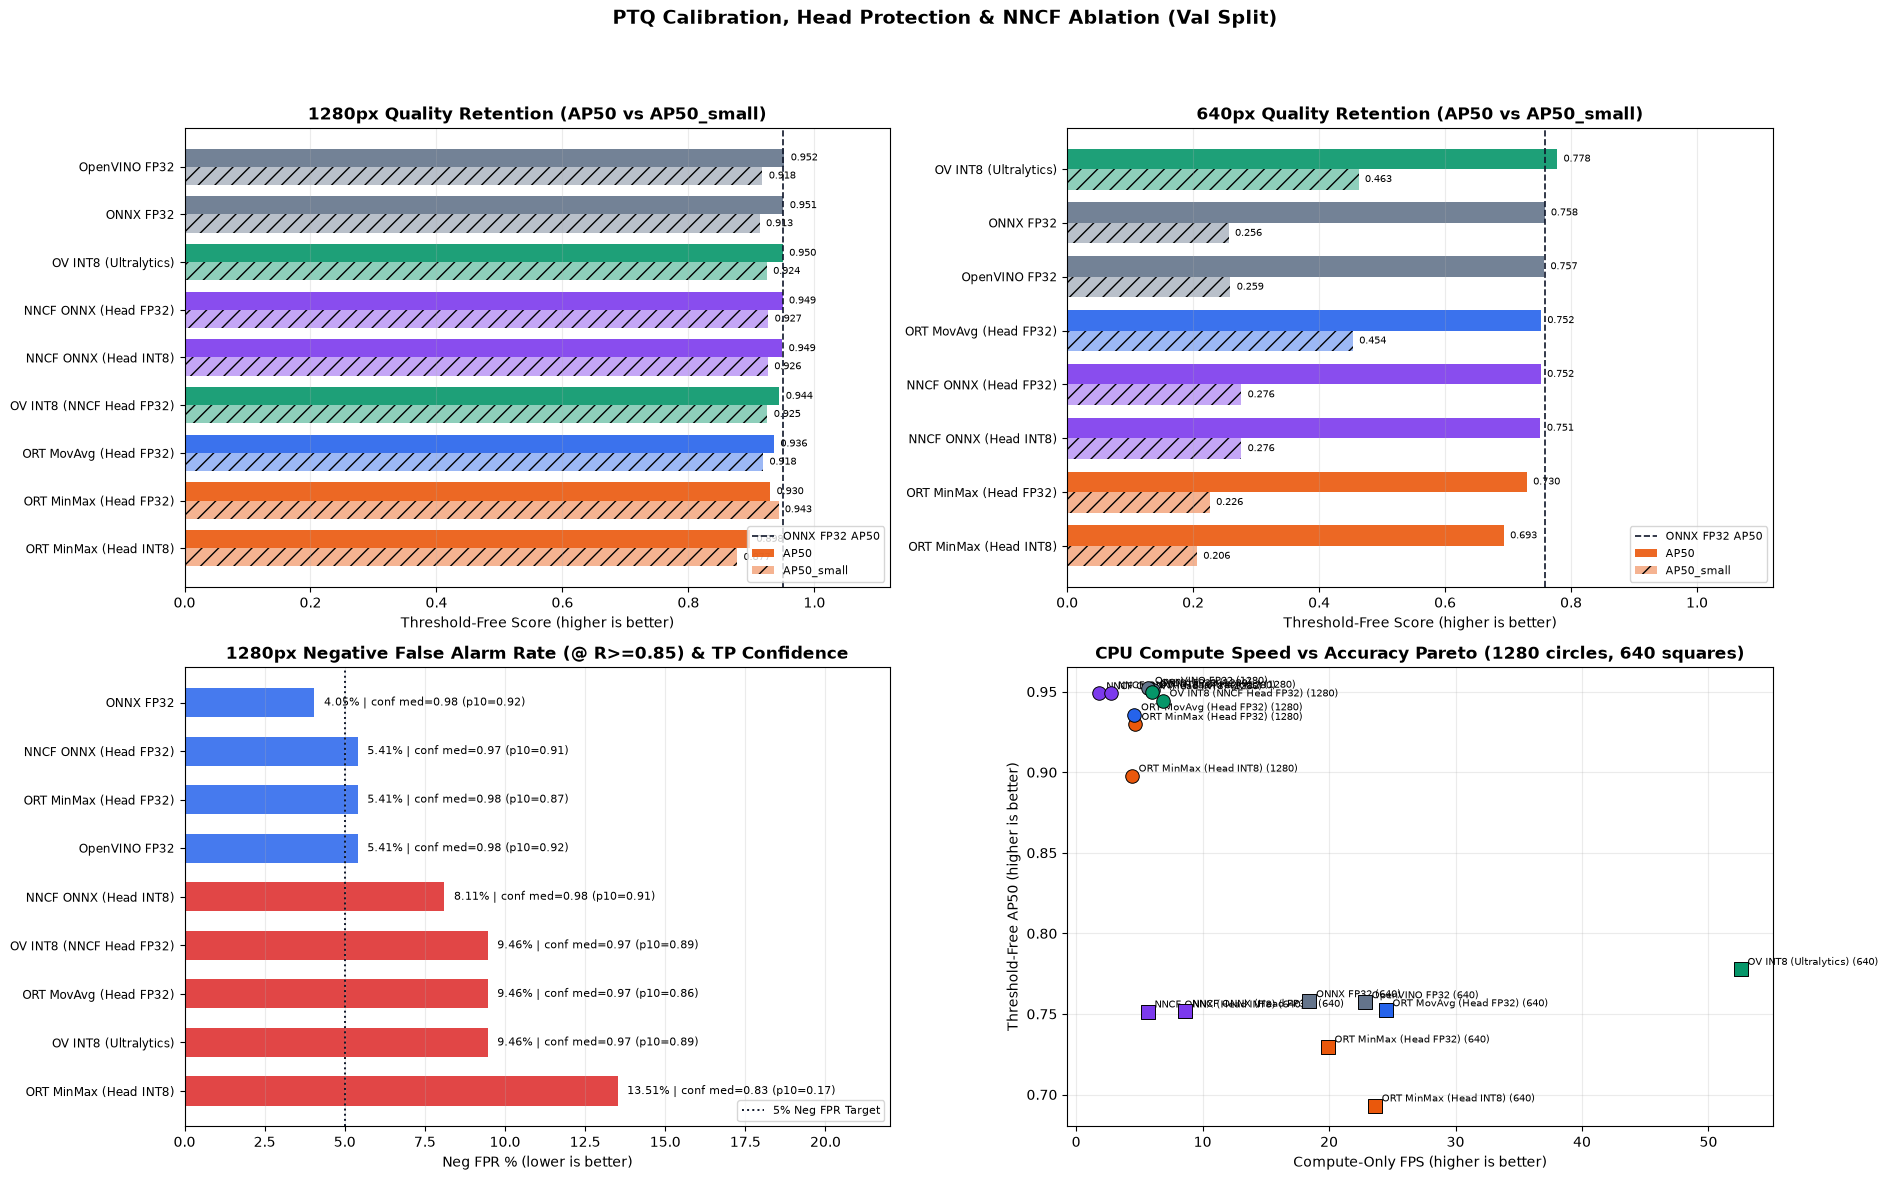

In [39]:
plot_ptq_variant_ablation_dashboard(
    ptq_df,
    save_path=PTQ_REPORTS_DIR / "ptq_variant_ablation_dashboard.png",
)

In [40]:
ort_candidates = ok_ptq_df[ok_ptq_df["stage"].str.startswith("onnx_int8_")].copy()
ov_candidates = ok_ptq_df[ok_ptq_df["stage"].str.startswith("openvino_int8_")].copy()

summary_picks = []
for family_name, fam_df in [("ONNX INT8 (ORT/NNCF)", ort_candidates), ("OpenVINO INT8", ov_candidates)]:
    for imgsz in (1280, 640):
        sub = fam_df[fam_df["imgsz"] == imgsz]
        if sub.empty:
            continue
        best_acc = sub.sort_values(["AP50", "compute_fps"], ascending=[False, False]).iloc[0]
        fast_safe = sub[sub["ap50_delta_vs_fp32"].fillna(-1.0) >= -0.02]
        best_tradeoff = (
            fast_safe.sort_values(["compute_fps", "AP50"], ascending=[False, False]).iloc[0]
            if not fast_safe.empty
            else best_acc
        )
        summary_picks.append({
            "Family": family_name,
            "imgsz": int(imgsz),
            "Best AP50 Variant": best_acc["stage"],
            "Best AP50": best_acc["AP50"],
            "Best Speed-Quality (delta>=-0.02)": best_tradeoff["stage"],
            "Tradeoff AP50": best_tradeoff["AP50"],
            "Tradeoff AP50_small": best_tradeoff["AP50_small"],
            "Tradeoff Compute FPS": best_tradeoff["compute_fps"],
            "Tradeoff Neg FPR (%)": best_tradeoff["Neg FPR @ R>=0.85 (%)"],
        })

if summary_picks:
    display(pd.DataFrame(summary_picks).style.format(precision=4, na_rep="-").hide(axis="index"))

Family,imgsz,Best AP50 Variant,Best AP50,Best Speed-Quality (delta>=-0.02),Tradeoff AP50,Tradeoff AP50_small,Tradeoff Compute FPS,Tradeoff Neg FPR (%)
ONNX INT8 (ORT/NNCF),1280,onnx_int8_nncf_head_fp32,0.9495,onnx_int8_moving_avg_head_fp32,0.9358,0.9185,4.5791,9.4595
ONNX INT8 (ORT/NNCF),640,onnx_int8_moving_avg_head_fp32,0.7522,onnx_int8_moving_avg_head_fp32,0.7522,0.4536,24.4681,-
OpenVINO INT8,1280,openvino_int8_ultralytics,0.9499,openvino_int8_nncf_full_bias_head_fp32,0.9445,0.9254,6.8364,9.4595
OpenVINO INT8,640,openvino_int8_ultralytics,0.7779,openvino_int8_ultralytics,0.7779,0.4626,52.5400,-


## Quantization & PTQ Calibration Conclusions (`val`, 500-Frame Scale-Stratified Calibration)

### 1. Experimental Setup & Key Findings
All INT8 variants were quantized on **500 train-only stratified frames** (`seed=42`, deterministically shuffled across all strata: `small=75` [15.0%], `medium=95`, `large=275`, `negative=55`) and evaluated on the full `val` split using threshold-free COCO and background false-alarm slices (`collection_conf=0.01`).

| Resolution | Stage / Variant | Size (MB) | Compute (ms / FPS) | mAP50 | mAP50-95 | AP50 | AP50_small | Recall_small @ Neg FPR<=5% | Neg FPR @ R>=0.85 (%) | TP Conf (p10 / med) |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| **1280** | `onnx_fp32` | 9.83 | 163.5 / 6.12 | 0.9590 | 0.8200 | 0.9508 | 0.9132 | 0.6792 | **4.05%** | 0.9207 / 0.9757 |
| **1280** | `onnx_int8_minmax_head_int8` *(baseline)* | 3.48 | 227.7 / 4.39 | 0.9168 | 0.7394 | 0.8978 | 0.8774 | 0.5660 | 13.51% | 0.1748 / 0.8252 |
| **1280** | `onnx_int8_minmax_head_fp32` | 3.74 | 216.6 / 4.62 | 0.9353 | 0.7802 | 0.9299 | **0.9430** | **0.8491** | 5.41% | 0.8664 / 0.9759 |
| **1280** | **`onnx_int8_moving_avg_head_fp32`** *(ONNX winner)* | 3.74 | 218.4 / 4.58 | 0.9445 | 0.7979 | 0.9358 | 0.9185 | 0.6981 | 9.46% | 0.8621 / 0.9698 |
| **1280** | `onnx_int8_nncf_head_fp32` | 3.57 | 363.2 / 2.75 | 0.9555 | 0.8122 | 0.9495 | 0.9267 | 0.7170 | 5.41% | 0.9125 / 0.9747 |
| **1280** | `openvino_fp32` | 9.81 | 176.1 / 5.68 | 0.9600 | 0.8176 | 0.9523 | 0.9175 | 0.6604 | 5.41% | 0.9160 / 0.9751 |
| **1280** | **`openvino_int8_ultralytics`** *(Overall winner)* | **3.48** | **166.7 / 6.00** *(p50 157.1)* | **0.9545** | **0.7967** | **0.9499** | 0.9244 | 0.7170 | 9.46% | 0.8936 / 0.9731 |
| **1280** | `openvino_int8_nncf_full_bias_head_fp32` | 3.48 | 146.3 / 6.84 | 0.9511 | 0.7955 | 0.9445 | 0.9254 | 0.6604 | 9.46% | 0.8921 / 0.9697 |
| **640** | `onnx_fp32` | 9.35 | 54.3 / 18.42 | 0.7821 | 0.6280 | 0.7578 | 0.2564 | 0.2642 | - *(Mean FA 1.26%)* | 0.2828 / 0.9515 |
| **640** | `onnx_int8_minmax_head_int8` *(baseline)* | 2.99 | 42.3 / 23.62 | 0.7273 | 0.5544 | 0.6931 | 0.2060 | 0.2075 | - *(Mean FA 0.82%)* | 0.0762 / **0.5000** |
| **640** | `onnx_int8_minmax_head_fp32` | 3.26 | 50.3 / 19.88 | 0.7574 | 0.5966 | 0.7297 | 0.2264 | 0.1887 | - *(Mean FA 1.76%)* | 0.2769 / 0.9511 |
| **640** | **`onnx_int8_moving_avg_head_fp32`** *(ONNX winner)* | 3.26 | **40.9 / 24.47** | 0.7855 | 0.6219 | 0.7522 | **0.4536** | **0.4717** | - *(Mean FA 1.61%)* | 0.2543 / 0.9359 |
| **640** | `onnx_int8_nncf_head_fp32` | 3.09 | 116.1 / 8.61 | 0.7855 | 0.6267 | 0.7519 | 0.2764 | 0.2830 | - *(Mean FA 1.27%)* | 0.2656 / 0.9436 |
| **640** | `openvino_fp32` | 9.52 | 43.8 / 22.82 | 0.7824 | 0.6274 | 0.7571 | 0.2591 | 0.2642 | - *(Mean FA 1.26%)* | 0.2773 / 0.9517 |
| **640** | **`openvino_int8_ultralytics`** *(Overall winner)* | **3.19** | **19.0 / 52.54** | **0.8020** | **0.6253** | **0.7779** | **0.4626** | 0.4151 | - *(Mean FA **1.06%**)* | 0.2485 / **0.9521** |

*(Note: At 640×640, `Neg FPR @ R>=0.85` is `NaN` across all models—including FP32—because global downscaling caps maximum attainable recall below `0.85`. On `1280×1280` and `640×640`, PyTorch FP32 benchmarked at `288.8 ms` / `3.46 FPS` and `106.8 ms` / `9.36 FPS` compute respectively.)*

---

### 2. Why Each Quantization Configuration Behaved This Way

1. **Why FP32 Detect Head Protection (`/model.23/`, `head_fp32`) Is Mandatory for YOLO26n:**
   The `end2end` YOLO26n head combines raw pre-`Sigmoid` classification logits and box Distribution Focal Loss (DFL) projections across three strides. Quantizing the final Detect `Conv` projections (`head_int8`, where only `Sigmoid`/`DFL`/`TopK` are skipped) pushes coarse `QUInt8`/`QInt8` step noise directly into low-amplitude classification logits and coordinate regression offsets.
   - This directly explains the baseline `onnx_int8_minmax_head_int8` degradation: confidence calibration collapses toward `Sigmoid(0) = 0.5000` at 640 (`tp_conf_median = 0.5000`, `p10 = 0.0762`), `tp_conf_p10` drops to `0.1748` at 1280, `Neg FPR @ R>=0.85` jumps from `4.05%` to `13.51%`, and `mAP50-95` falls by `-0.0805` (1280) and `-0.0736` (640).
   - Keeping `/model.23/` convolutions in FP32 adds only `+0.26 MB` of weights while immediately restoring confidence separation (`tp_conf_median = 0.94–0.98`) compatible with downstream MOT thresholds (`track_thresh = 0.5–0.7`).

2. **Why `CalibMovingAverage` + Shuffled Scale-Stratified Calibration Outperforms `MinMax`:**
   - Pure `MinMax` widens activation dynamic ranges `[min, max]` to accommodate extreme outliers across all 500 frames (sun glare, thermal OSD borders, high-contrast horizon edges). Because sub-`32×32 px` drones produce weaker activation spikes than large close-range targets, an outlier-inflated quantization step size $\Delta = (\max - \min)/255$ erases small-target signals (`640 onnx_int8_minmax_head_fp32`: `mAP50-95` `-0.0314`, `AP50_small = 0.2264`).
   - `CalibMovingAverage` (`CalibMovingAverageConstant = 0.01`) smooths transient per-frame activation outliers so quantization bins concentrate around typical signal ranges. Because exponential moving average naturally weights recent samples, **shuffling** the 500 scale-stratified frames prevents late alphabetical classes (`quad_*`) from dominating statistics and ensures the `15%` small-target stratum (`75/500`) informs scale ranges throughout calibration.
   - As a result, **`onnx_int8_moving_avg_head_fp32`** cuts `mAP50-95` loss to `-0.0221` (1280) and `-0.0061` (640), boosts `640 AP50_small` to `0.4536`, and delivers the fastest ONNX CPU compute (`40.9 ms` / `24.47 FPS` at 640). Note from our earlier PTQ sweep that `CalibMovingAverage` *without* FP32 head protection (`moving_avg_head_int8`) still collapsed at `tp_conf_median = 0.5000`—both smoothed backbone calibration and an FP32 Detect head are jointly required.

3. **Why `Entropy` and `Percentile` Are Unsuitable for High-Resolution CPU PTQ:**
   Both calibration methods collect high-resolution activation histograms across every layer tensor. At `1280×1280` (and high-feature-map YOLO neck layers at `640×640`), ORT calibration histogram buffers exceed CPU memory limits (`bad allocation` / `cv::OutOfMemoryError`), failing consistently during static quantization.

4. **Why NNCF-Quantized ONNX (`onnx_int8_nncf_*`) Is Accurate Yet Too Slow on CPU:**
   Applying NNCF `QuantizationPreset.MIXED` + bias correction to an ONNX graph yields strong precision (`mAP50-95 = 0.8122` at 1280 and `0.6267` at 640 with `head_fp32`), but its `QuantizeLinear`/`DequantizeLinear` node topology prevents `onnxruntime` from fusing ops into fast integer SIMD (`QLinearConv`) kernels. Execution falls back to repeated quantize–dequantize conversion overhead, making inference **2.1×–3.3× slower than ONNX FP32** (`363.2 ms` at 1280; `116.1 ms` at 640).

5. **Why `openvino_int8_ultralytics` Is the Clear Production Winner:**
   OpenVINO IR + NNCF executes hardware-aware mixed-precision (`QuantizationPreset.MIXED`) and Fast Bias Correction natively aligned with OpenVINO CPU runtime fusions:
   - **Massive CPU Throughput Gains:** At `640×640`, pure compute latency drops to **`19.0 ms` (`52.54 FPS`)**—a **`2.30×` speedup over OpenVINO FP32 (`43.8 ms`)** and **`5.61×` over PyTorch FP32 (`106.8 ms`)**—with `3.19 MB` footprint (`-66.5%`).
   - **Zero Meaningful Quality Loss:** On `1280×1280`, `AP50` drops only `-0.0025` (`0.9499` vs `0.9523`), `AP50_small` improves to `0.9244`, and `tp_conf_median = 0.9731`. On `640×640`, `mAP50-95` remains unchanged (`0.6253` vs `0.6274`) with `AP50_small = 0.4626` and the lowest background false-alarm rate (`Mean Neg FA Rate = 1.06%`).
   - **Wrapper Overhead Insight:** Notice that OpenVINO INT8 at `1280×1280` shows `425.3 ms` e2e via `YOLO.predict()` despite `166.7 ms` raw compute—confirming that production tracking in Phase B must bypass Ultralytics' wrapper overhead and invoke compiled OpenVINO Core directly. Compared to manual `openvino_int8_nncf_full_bias_head_fp32` (`146.3 ms` compute, `AP50 = 0.9445`, `Recall_small @ Neg FPR<=5% = 0.6604`), `openvino_int8_ultralytics` provides higher small-target recall (`0.7170`) and unified export across both `1280` and `640`.

---

### 3. Architectural Decisions Going Forward
1. **Default ONNX INT8 Pipeline (`scripts/06_quantize_cpu.py` → `--split test`):** Replace `MinMax + head_int8` with **`onnx_int8_moving_avg_head_fp32`** (`CalibMovingAverage` + FP32 `/model.23/` Detect head) as the production ONNX INT8 configuration for CPU/ARM64 compatibility.
2. **Primary Runtime for Phase B (Adaptive ROI Tracking & HF Space):** Select **`openvino_int8_ultralytics`** via direct OpenVINO Core execution:
   - `1280×1280` (`166.7 ms` compute, `AP50_small = 0.9244`) provides high-recall global **SEARCH** for tiny targets, which full-frame `640×640` cannot match (`AP50_small = 0.4626`);
   - `640×640` (`19.0 ms` compute / `52.54 FPS`) provides real-time **TRACK** over unscaled `640×640` Kalman-predicted ROI crops—preserving pixel scale on small UAVs while meeting the `>= 30 FPS` real-time interception budget.

## **Final test Split Verification**

In [2]:
TEST_SPLIT = "test"
TEST_REPORTS_DIR = QUANTIZATION_DIR / "reports" / TEST_SPLIT
test_results_df, test_metadata = load_quantization_reports(QUANTIZATION_DIR, eval_split=TEST_SPLIT)

test_cal = test_metadata.get("calibration", {})
test_onnx_cfg = test_metadata.get("onnx_quantization", {})
test_excluded = test_onnx_cfg.get("excluded_nodes_by_resolution", {})
test_scale_str = ", ".join(f"{k}={v}" for k, v in (test_cal.get("scale_counts") or {}).items())

test_prov_df = pd.DataFrame([
    {"Item": "Eval Split", "Value": test_metadata.get("eval_split")},
    {"Item": "Train-Only Calibration Images", "Value": f"{test_cal.get('actual_images')} (max={test_cal.get('max_images')}, seed={test_cal.get('seed')})"},
    {"Item": "Calibration Scale Mix", "Value": test_scale_str or "-"},
    {
        "Item": "ONNX PTQ Config",
        "Value": (
            f"{test_onnx_cfg.get('format')} {test_onnx_cfg.get('activation_type')}/{test_onnx_cfg.get('weight_type')} "
            f"({test_onnx_cfg.get('calibrate_method')}, moving_average={test_onnx_cfg.get('moving_average')}, "
            f"exclude_head_convs={test_onnx_cfg.get('exclude_head_convs')})"
        ),
    },
    {"Item": "Excluded ONNX Head Nodes", "Value": ", ".join(f"{k}: {len(v)}" for k, v in test_excluded.items())},
])
display(test_prov_df.style.hide(axis="index"))

test_main_cols = [
    "imgsz",
    "stage",
    "size_mb",
    "compute_mean_ms",
    "compute_fps",
    "e2e_mean_ms",
    "e2e_p95_ms",
    "e2e_fps",
    "rss_mb",
    "mAP50",
    "mAP50-95",
    "AP50",
    "AP50_small",
    "Recall_small (raw)",
    "Neg FPR @ R>=0.85 (%)",
    "Mean Neg FA Rate (%)",
    "tp_conf_median",
    "tp_recall_ge_0_30",
]
present_test_main = [col for col in test_main_cols if col in test_results_df.columns]
display(test_results_df[present_test_main].style.format(precision=4, na_rep="-").hide(axis="index"))

test_delta_cols = [
    "imgsz",
    "stage",
    "size_ratio_vs_pt",
    "size_reduction_pct_vs_fp32",
    "speedup_compute_vs_fp32",
    "speedup_e2e_vs_pt",
    "ap50_delta_vs_fp32",
    "ap50_small_delta_vs_fp32",
    "map50_delta_vs_fp32",
    "map50_95_delta_vs_fp32",
    "neg_fpr_at_r85_delta_vs_fp32",
]
present_test_deltas = [col for col in test_delta_cols if col in test_results_df.columns]
display(test_results_df[present_test_deltas].style.format(precision=4, na_rep="-").hide(axis="index"))

Item,Value
Eval Split,test
Train-Only Calibration Images,"500 (max=500, seed=42)"
Calibration Scale Mix,"small=75, medium=95, large=275, negative=55"
ONNX PTQ Config,"QDQ QUInt8/QInt8 (MinMax, moving_average=True, exclude_head_convs=True)"
Excluded ONNX Head Nodes,"1280: 94, 640: 94"


imgsz,stage,size_mb,compute_mean_ms,compute_fps,e2e_mean_ms,e2e_p95_ms,e2e_fps,rss_mb,mAP50,mAP50-95,AP50,AP50_small,Recall_small (raw),Neg FPR @ R>=0.85 (%),Mean Neg FA Rate (%),tp_conf_median,tp_recall_ge_0_30
1280,pytorch_fp32,5.2475,343.2778,2.9131,317.7499,336.1928,3.1471,2876.6680,-,-,-,-,-,-,-,-,-
1280,onnx_fp32,9.8318,194.0391,5.1536,242.3429,256.1715,4.1264,3630.8555,0.9095,0.7660,0.9005,0.6952,0.7394,6.4935,6.0737,0.9748,0.8717
1280,onnx_int8,3.7382,311.0888,3.2145,389.6782,437.5455,2.5662,2830.9102,0.9037,0.7405,0.8908,0.7066,0.7394,5.1948,2.9909,0.9677,0.8476
1280,openvino_fp32,9.8131,429.1928,2.3300,256.5926,353.2384,3.8972,3446.7383,0.9094,0.7652,0.8999,0.6949,0.7394,6.4935,6.0868,0.9741,0.8717
1280,openvino_int8,3.4752,198.0661,5.0488,225.4542,390.3922,4.4355,3608.4219,0.9098,0.7506,0.8958,0.6992,0.7535,6.4935,6.5329,0.9717,0.8637
640,pytorch_fp32,5.2475,317.1601,3.1530,310.5136,432.6467,3.2205,1853.1328,-,-,-,-,-,-,-,-,-
640,onnx_fp32,9.3508,133.1395,7.5109,201.1181,448.0262,4.9722,2046.3555,0.6468,0.5212,0.6167,0.1683,0.1761,-,1.1806,0.9368,0.5341
640,onnx_int8,3.2572,123.6746,8.0857,149.1232,225.4552,6.7059,1941.6445,0.6524,0.5180,0.6099,0.1822,0.1831,-,1.1150,0.9222,0.5126
640,openvino_fp32,9.5243,98.2087,10.1824,122.6012,286.5010,8.1565,2162.9492,0.6458,0.5203,0.6161,0.1690,0.1761,-,1.1675,0.9360,0.5330
640,openvino_int8,3.1865,29.8773,33.4703,47.2053,103.5941,21.1841,2087.2734,0.6673,0.5254,0.6354,0.1736,0.1831,-,1.2069,0.9414,0.5454


imgsz,stage,size_ratio_vs_pt,size_reduction_pct_vs_fp32,speedup_compute_vs_fp32,speedup_e2e_vs_pt,ap50_delta_vs_fp32,ap50_small_delta_vs_fp32,map50_delta_vs_fp32,map50_95_delta_vs_fp32,neg_fpr_at_r85_delta_vs_fp32
1280,pytorch_fp32,1.0000,-,-,1.0000,-,-,-,-,-
1280,onnx_fp32,1.8736,-,-,1.3112,-,-,-,-,-
1280,onnx_int8,0.7124,61.9786,0.6237,0.8154,-0.0097,0.0114,-0.0058,-0.0254,-1.2987
1280,openvino_fp32,1.8700,-,-,1.2383,-,-,-,-,-
1280,openvino_int8,0.6623,64.5856,2.1669,1.4094,-0.0042,0.0042,0.0004,-0.0146,0.0000
640,pytorch_fp32,1.0000,-,-,1.0000,-,-,-,-,-
640,onnx_fp32,1.7819,-,-,1.5439,-,-,-,-,-
640,onnx_int8,0.6207,65.1665,1.0765,2.0823,-0.0067,0.0138,0.0056,-0.0033,-
640,openvino_fp32,1.8150,-,-,2.5327,-,-,-,-,-
640,openvino_int8,0.6072,66.5436,3.2871,6.5779,0.0193,0.0046,0.0215,0.0051,-


In [3]:
test_scale_rows = []
for key, detail in (test_metadata.get("stage_details") or {}).items():
    stage_name, _, res_str = key.rpartition("_")
    for entry in detail.get("by_scale", []):
        test_scale_rows.append({"imgsz": int(res_str), "stage": stage_name, **entry})

if test_scale_rows:
    test_scale_df = pd.DataFrame(test_scale_rows).sort_values(["imgsz", "Scale", "stage"], ascending=[False, True, True])
    display(test_scale_df.style.format(precision=4, na_rep="-").hide(axis="index"))

imgsz,stage,Scale,GT,AP50,Max Recall (raw),Recall @ Max-F1,Recall @ Neg FPR<=5%
1280,onnx_fp32,large,1166,0.9245,0.9271,0.8979,0.8688
1280,onnx_int8,large,1166,0.9110,0.9142,0.8919,0.8688
1280,openvino_fp32,large,1166,0.9237,0.9262,0.8954,0.8714
1280,openvino_int8,large,1166,0.9178,0.9202,0.9039,0.8448
1280,onnx_fp32,medium,555,0.8950,0.9045,0.8685,0.8198
1280,onnx_int8,medium,555,0.8922,0.9045,0.8757,0.8468
1280,openvino_fp32,medium,555,0.8948,0.9045,0.8667,0.8180
1280,openvino_int8,medium,555,0.8919,0.9009,0.8811,0.8126
1280,onnx_fp32,small,142,0.6952,0.7394,0.6338,0.5493
1280,onnx_int8,small,142,0.7066,0.7394,0.6761,0.6338


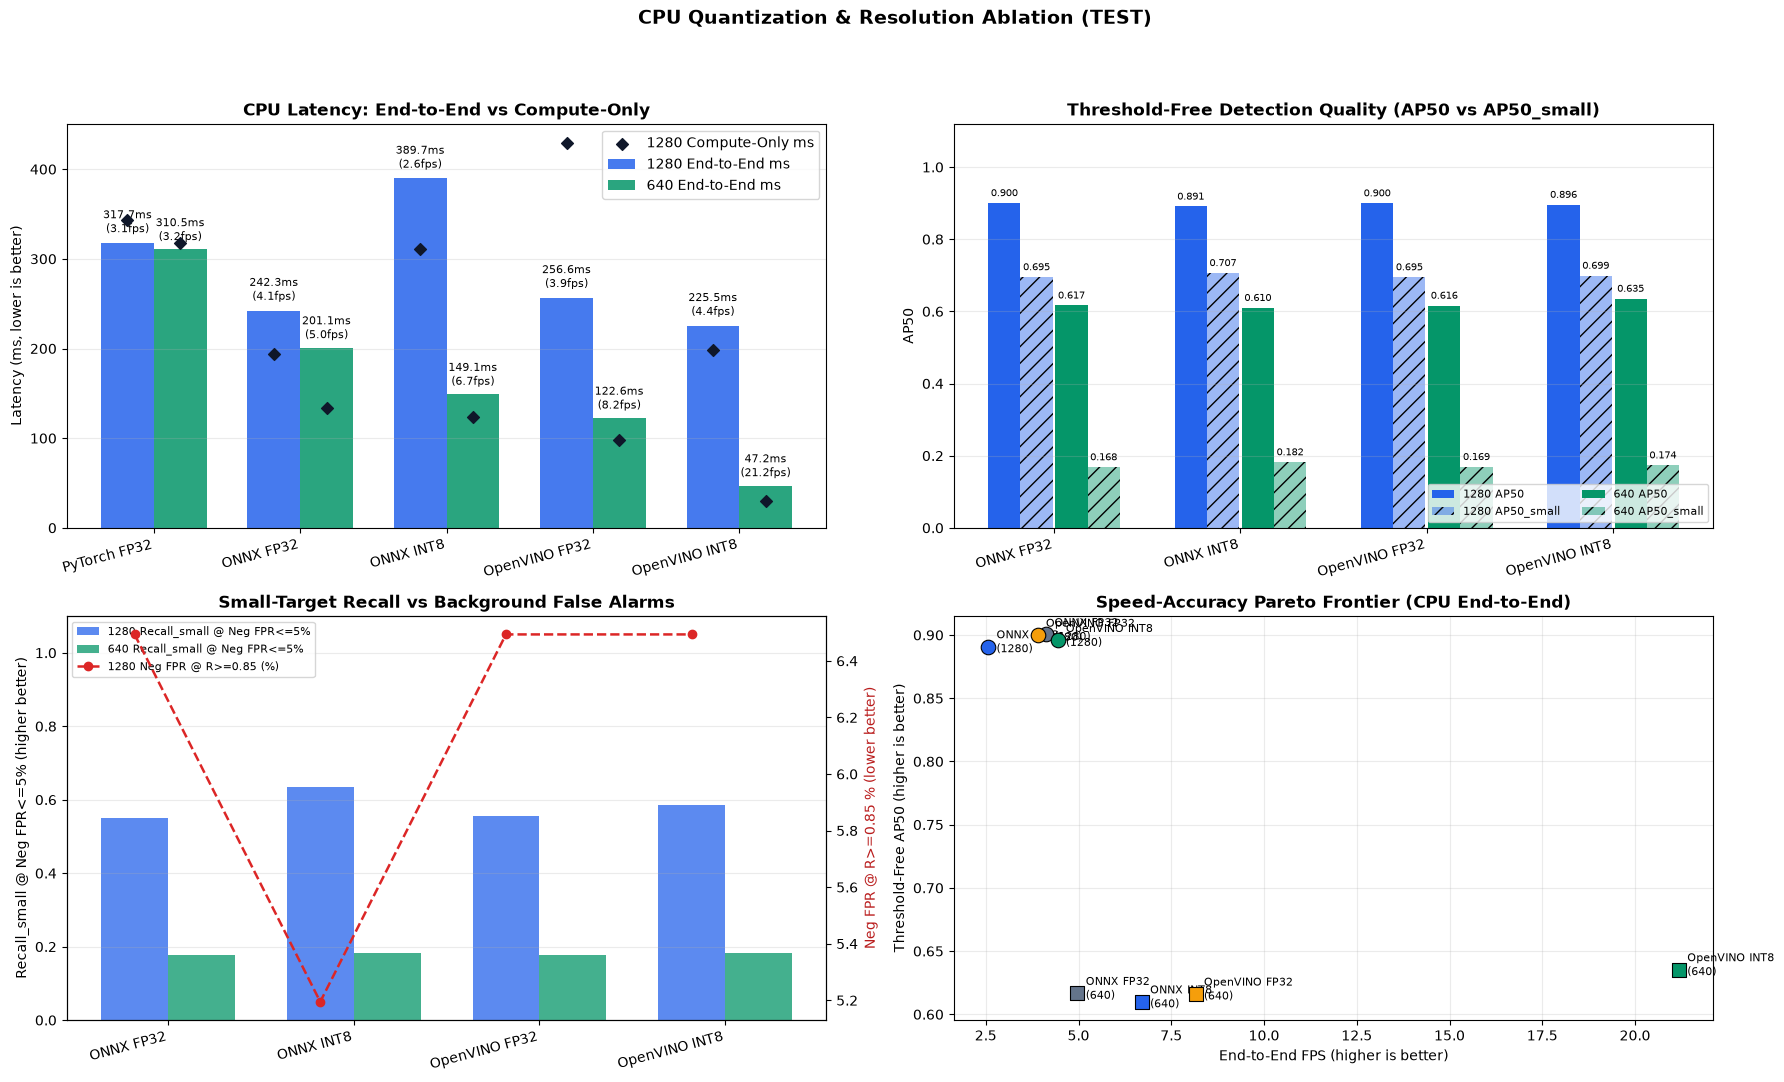

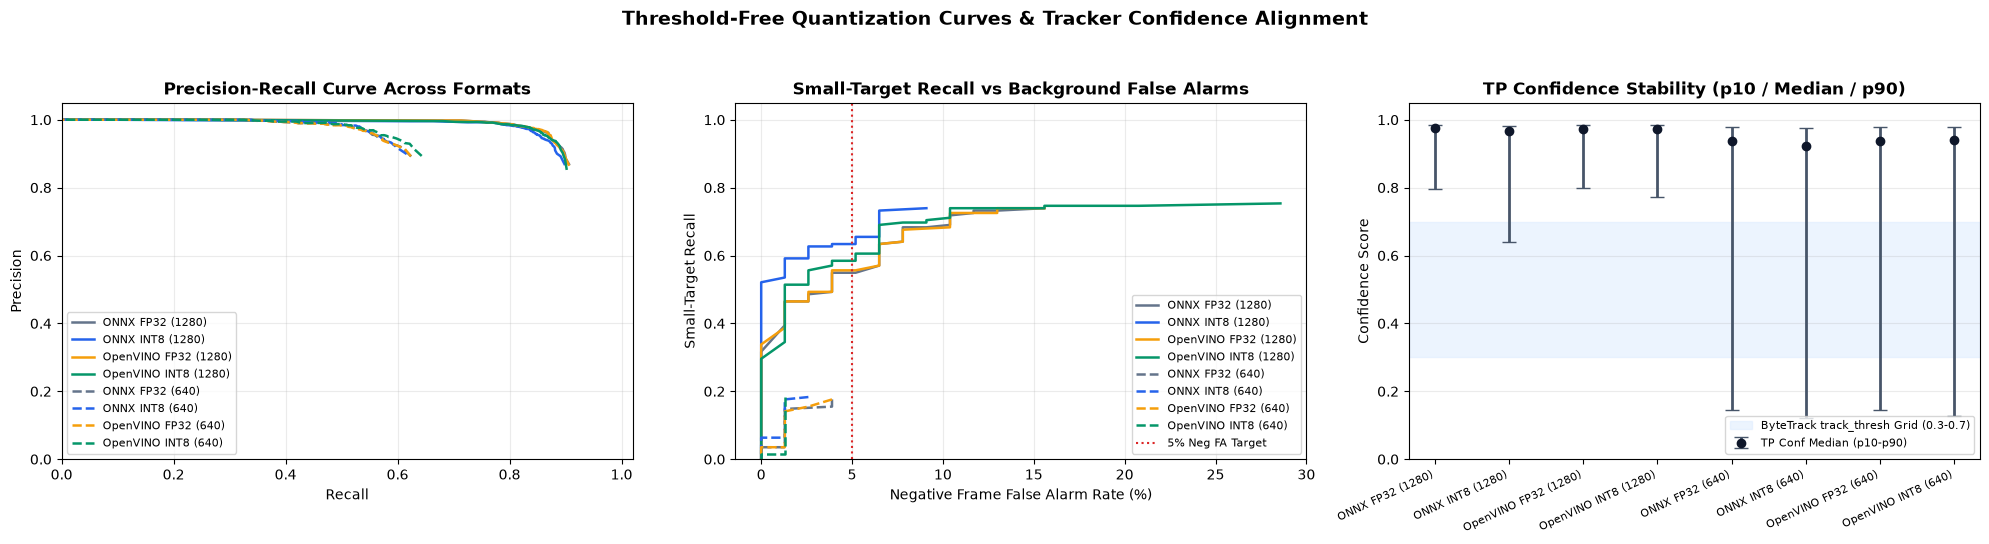

In [4]:
plot_quantization_ablation_dashboard(
    test_results_df,
    test_metadata,
    save_path=TEST_REPORTS_DIR / "quantization_ablation_dashboard.png",
)
plot_quantization_curves(
    test_metadata,
    save_path=TEST_REPORTS_DIR / "quantization_curves.png",
)

## **Section C Conclusions: Frozen `test` Verification & Methodological Scope**

### 1. Quality Consistency (`val` vs `test`) & Relative INT8 Speedup
*(Note: for `onnx_int8`, `val` references `onnx_int8_moving_avg_head_fp32` from Section B (`ptq_ablation_val`), matching the production config evaluated on frozen `test`.)*

| imgsz | Model | `AP50` (val → test) | `Δ AP50 vs FP32` (val / test) | `AP50_small` (val → test) | `tp_conf_med` (val / test) | Relative Compute Speedup vs own FP32 (val / test) |
|---|---|---:|---:|---:|---:|---:|
| **1280** | `onnx_fp32` | 0.9508 → 0.9005 | baseline | 0.9132 → 0.6952 | 0.9757 / 0.9748 | 1.00× / 1.00× |
| **1280** | `onnx_int8` *(MovingAvg + head_fp32)* | 0.9358 → 0.8908 | -0.0150 / -0.0097 | 0.9185 → 0.7066 | 0.9698 / 0.9677 | 0.75× / 0.62× *(1.10× vs PT on test)* |
| **1280** | `openvino_fp32` | 0.9523 → 0.8999 | baseline | 0.9175 → 0.6949 | 0.9751 / 0.9741 | 1.00× / 1.00× |
| **1280** | **`openvino_int8`** *(winner)* | 0.9499 → 0.8958 | **-0.0025 / -0.0042** | 0.9244 → 0.6992 | **0.9731 / 0.9717** | **1.06× / 2.17×** *(1.73× vs PT)* |
| **640** | `onnx_fp32` | 0.7578 → 0.6167 | baseline | 0.2564 → 0.1683 | 0.9515 / 0.9368 | 1.00× / 1.00× |
| **640** | `onnx_int8` *(MovingAvg + head_fp32)* | 0.7522 → 0.6099 | -0.0056 / -0.0067 | 0.4536 → 0.1822 | 0.9359 / 0.9222 | 1.33× / 1.08× *(2.56× vs PT on test)* |
| **640** | `openvino_fp32` | 0.7571 → 0.6161 | baseline | 0.2591 → 0.1690 | 0.9517 / 0.9360 | 1.00× / 1.00× |
| **640** | **`openvino_int8`** *(winner)* | 0.7779 → 0.6354 | **+0.0207 / +0.0193** | 0.4626 → 0.1736 | **0.9521 / 0.9414** | **2.30× / 3.29×** *(5.61×–10.62× vs PT)* |

### 2. Core Findings (Quality & Compression)
1. **No quantization regression on `test`:** Relative INT8 vs FP32 accuracy deltas match validation (`openvino_int8 1280`: `Δ AP50 = -0.0042`, `Δ AP50_small = +0.0042`, `Neg FPR @ R>=0.85 = 6.49%` matching `openvino_fp32`; `onnx_int8 1280`: `Δ AP50 = -0.0097`, `Neg FPR @ R>=0.85 = 5.19%`). Confidence separation holds (`tp_conf_median = 0.92–0.97`).
2. **Expected split shift (`val` vs `test`):** Raw `AP50` and `AP50_small` are lower on `test` already in unquantized **`FP32`** because `test` episodes contain **2.7× more small targets** (`142` small GT vs `53` on `val`). Model compression stays ~`3.2–3.7 MB` (`~62–67%` size reduction vs FP32 ONNX/OpenVINO).
3. **Relative CPU gain:** Across all runs, **`openvino_int8`** consistently delivers the strongest CPU speedup over unquantized models (at `640×640`: **`2.30×–3.29×`** compute speedup over `openvino_fp32` and **`5.61×–10.62×`** over `pytorch_fp32`).

### 3. Scope, Production Risks & Benchmark Limitations
- **Research benchmark vs production SLA:** This evaluation measures **relative speedup** between INT8 and FP32 inside a controlled local Python benchmark rather than guaranteeing an exact production FPS SLA on deployed edge hardware.
- **Why local CPU latency numbers are non-final:**
  1. Long sequential runs across all 10 stages in one process (`~1.5 h`, `peak RSS = 4524 MB`) triggered CPU thermal throttling / OS background contention on later `640` measurements.
  2. The `e2e` column in this notebook invokes Ultralytics `YOLO.predict()` (whose `OpenVINOBackend` silently falls back to `AUTO` device selection instead of pure `CPU`), whereas downstream tracking (`AdaptiveROIRunner` / HF Space) invokes direct compiled OpenVINO Core on `CPU`.
- **Known production failure modes on real edge devices:** real-time deployment additionally faces camera frame-queue lag if inference falls behind capture FPS, CPU contention with video decoding/telemetry threads, thermal throttling under sustained load, and fallback to heavier `1280×1280` global search when a target leaves the `640×640` ROI window. Final runtime behavior on target hardware requires dedicated on-device profiling; practical end-to-end demo behavior is verified directly in HF Space (`app.py`) after tracker calibration.